MCP (Model Context Protocol) 是由 Anthropic 推出的开放标准，用于便捷的将AI应用连接外部系统。

在没有MCP的时候，必须手动定义工具，用工具实现文件操作、web搜索、查询航班、查询天气等功能，从而让AI连接外部系统。

这就存在两个问题：
- 不同Agent可能有同样的tool需求，每次都重复定义，复用性差
- 全世界有各种不同的服务，不同服务接口不同，定义Tool非常麻烦

MCP就像是AI世界的USB接口协议：
- 所有外部服务提供者都可以遵循MCP协议提供Tool，分享自己的Tool服务
- AI应用基于MCP协议对接任意遵循MCP的外部服务，无需自己定义Tool

这样一来就解决了重复定义工具的复用性问题、以及对接全世界各种公共服务的问题。
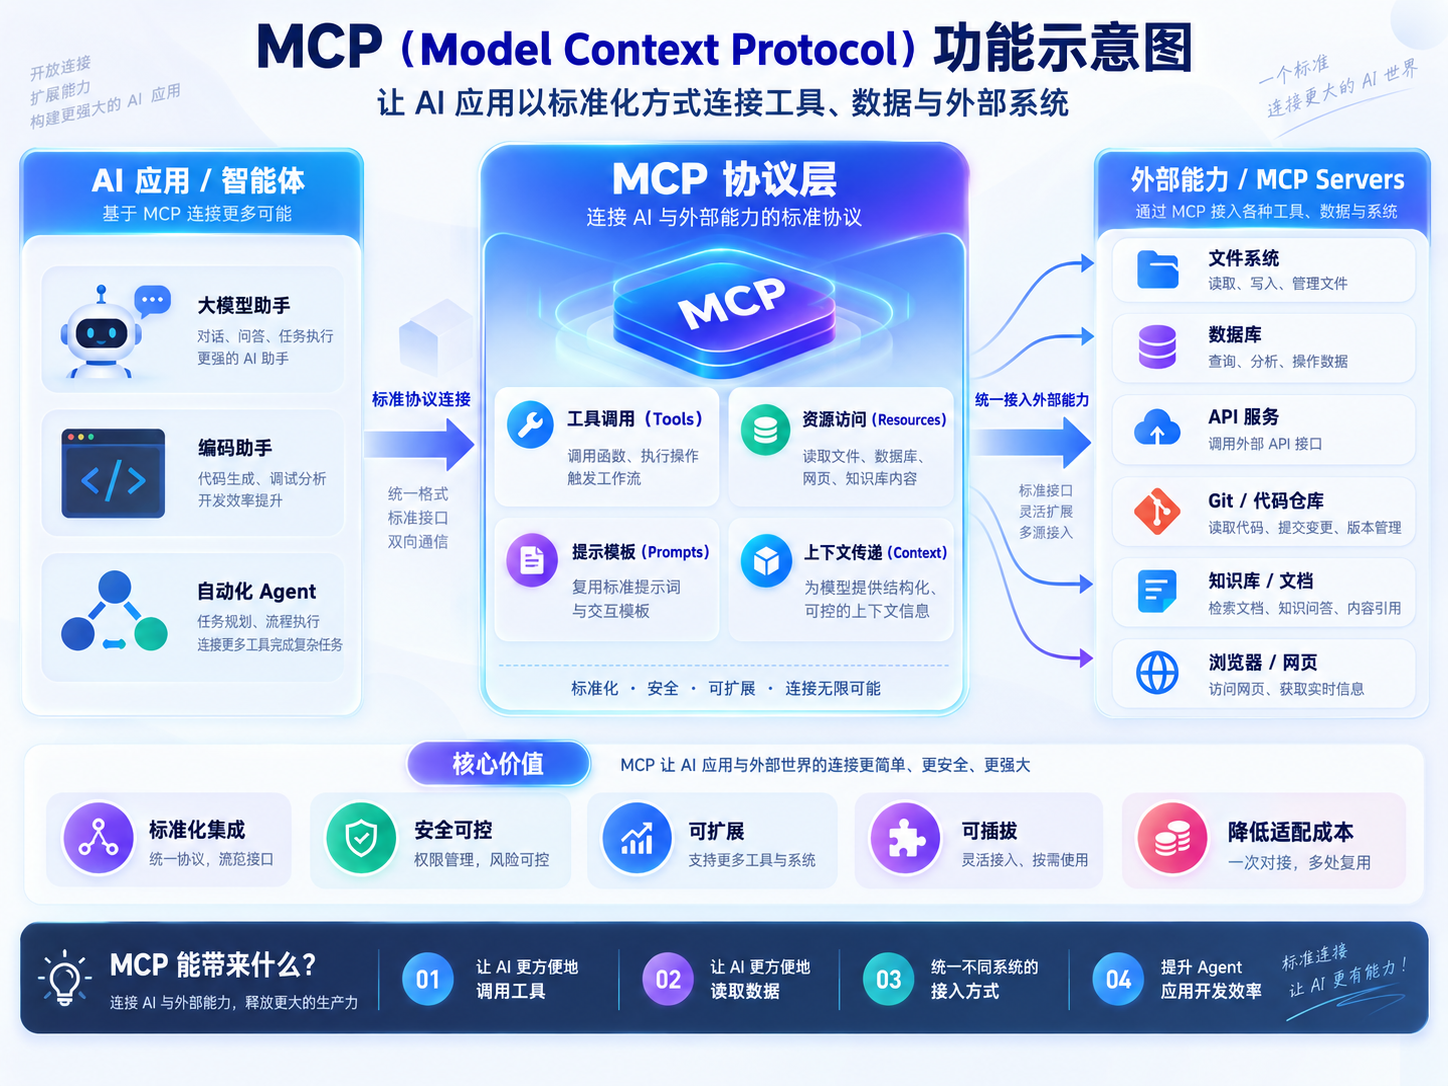

# 1. MCP核心概念

在MCP中有三个核心概念：
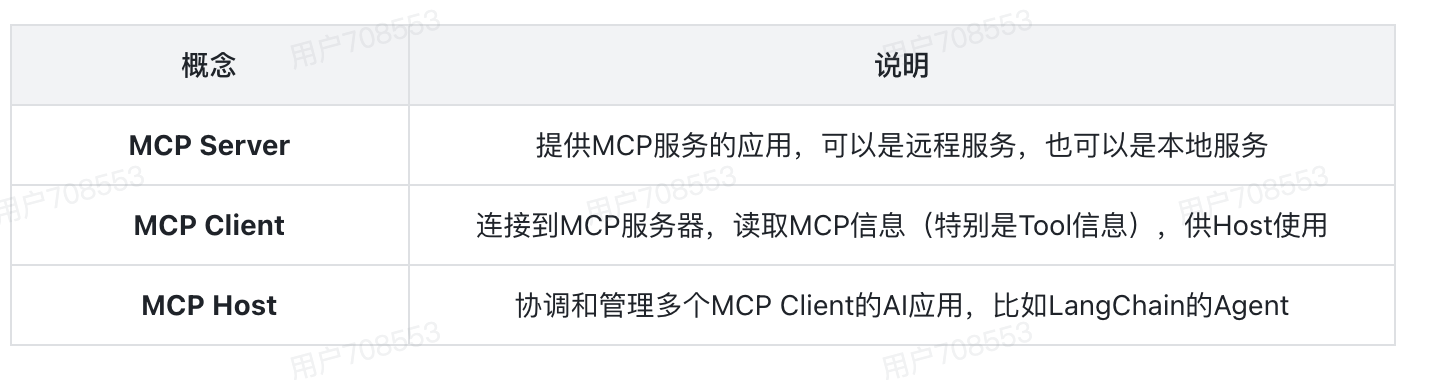

例如，一个AI应用，也就是MCP Host，它需要三个功能：
- 文件操作
- 数据库操作
- Sentry远程服务
此时，它可以定义3个不同的MCP Client，分别对接3个MCP Server，包含一个操作本地文件的MCP、一个访问数据库的MCP、一个访问Sentry服务的MCP
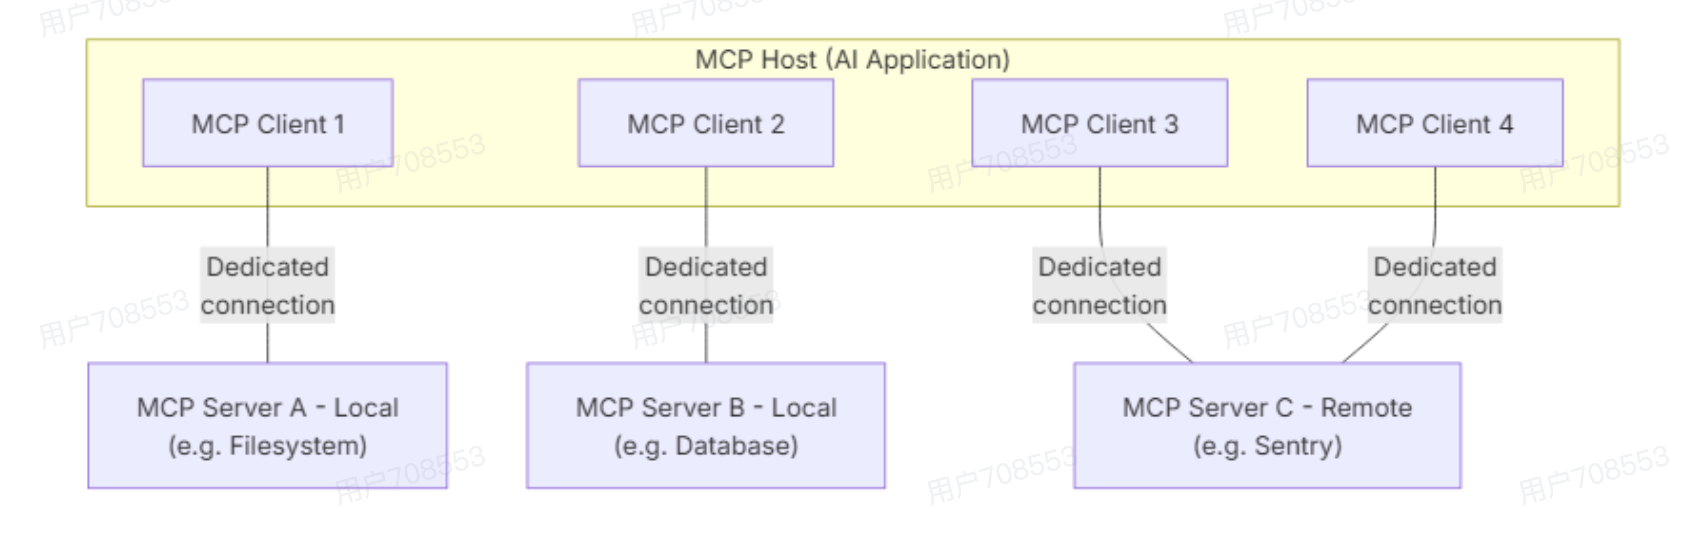

MCP Client 与 MCP Server之间有两种通信协议：
- stdio
- streamable_http

stdio就是标准输入输出，MCP Client运行时，分两种情况：
- 外部服务：Client会把这个MCP服务的脚本下载到本地，然后作为一个子进程运行。
- 本地服务：Client会把本地脚本直接加载，作为一个子进程运行
也就是说，stdio模式中，MCP Client 和 MCP Server之间的通信就是进程通信，没有网络延迟。

streamable_http其实就是可以用event stream来发送数据的http模式，本质还是Server Send Event，也就是SSE。也就是说MCP client通过发送http请求与MCP server交互。因此存在一定的网络延迟。

In [4]:
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file

True

In [5]:
import sys
import asyncio

# Fix for Windows issues in Jupyter notebooks
if sys.platform == "win32":
    # 1. Use ProactorEventLoop for subprocess support
    if not isinstance(asyncio.get_event_loop_policy(), asyncio.WindowsProactorEventLoopPolicy):
        asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())

    # 2. Redirect stderr to avoid fileno() error when launching MCP servers
    if "ipykernel" in sys.modules:
        sys.stderr = sys.__stderr__

## 2.1 Time MCP服务

In [10]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain_mcp_adapters.client import MultiServerMCPClient


model = init_chat_model(
    model="deepseek-flash",
    extra_body={"thinking": {"type": "disabled"}}
)

# 定义工具，用MCP获取工具
# 定义mcp client
client = MultiServerMCPClient(
    {
        "time": {
            "transport": "stdio",
            "command": "uvx",
            "args": [
                "mcp-server-time",
                "--local-timezone=Asia/Shanghai"
            ]
        }
    }
)

# 用client拉取tool
# 注意MultiServerMCPClient是异步的，结果都是协程对象，需要await
tools = await client.get_tools()
for tool in tools:
    print(f"Tool name: {tool.name}, description: {tool.description}")
    print("--------------------------------------------")

# 创建Agent，绑定模型和工具
agent = create_agent(
    model=model,
    tools=tools
)

# 由于MCP的Tool是异步的，所以必须用ainvoke调用Agent，是异步调用
response = await agent.ainvoke(
    {"messages": [HumanMessage("现在是什么时间")]}
)
print(response)

Tool name: get_current_time, description: Get current time in a specific timezone
--------------------------------------------
Tool name: convert_time, description: Convert time between timezones
--------------------------------------------
Tool name: get_time_ago, description: Get the time a given number of days, hours, minutes and seconds ago in a specific timezone
--------------------------------------------
{'messages': [HumanMessage(content='现在是什么时间', additional_kwargs={}, response_metadata={}, id='aabc3659-e9cc-439a-9482-d2b198df3584'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 42, 'prompt_tokens': 758, 'total_tokens': 800, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 512, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 512, 'prompt_cache_miss_tokens': 246}, 'model_provider': 'deepseek', 'model_name': 'd

## 2.2 Kiwi MCP服务

In [11]:
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage

# 连接Kiwi MCP服务器
client = MultiServerMCPClient(
    {
        "kiwi-com-flight-search": {
            "transport": "http",
            "url": "https://mcp.kiwi.com"
        },
        "time": {
            "transport": "stdio",
            "command": "uvx",
            "args": [
                "mcp-server-time",
                "--local-timezone=Asia/Shanghai"
            ]
        }
    }
)

# 注意MultiServerMCPClient是异步的，结果都是协程对象，需要await
tools = await client.get_tools()
for tool in tools:
    print(f"Tool name: {tool.name}, description: {tool.description}")
    print("--------------------------------------------")

Tool name: search-flight, description: # Search for flights

Searches Kiwi.com for available flights between two locations for the given dates and passengers. City or airport names are resolved automatically, so call this whenever the user wants to search for flights — whether they gave IATA codes or just place names.

## Result shape

Returns `{ query, currency, passengers, resultsCount, itineraries, searchTimeMs }`. Each item in `itineraries` has:
- `tripType` — `"oneway"` or `"return"`
- `price` (number) and `priceFormatted` (e.g. "123 EUR")
- `totalDurationSeconds`
- `bookingUrl` — the link to book the flight
- `imageId` — destination city id for a hero photo (https://images.kiwi.com/photos/600x600/{imageId}.jpg)
- `baggage` — total included baggage across all travelers: `{ personalItem, cabinBag, checkedBag }` (counts)
- `outbound` (and `inbound` for return flights), each a leg with: `route` (list of airport codes including layovers, e.g. ["PRG","MAD","BCN"]), `departureTime` / `a

In [12]:
agent = create_agent(
    model="deepseek-flash",
    tools=tools,
    system_prompt="You are a travel agent. Help user find best flights. No follow up questions. If the user uses Chinese, use zh-cn as the locale value."
)

response = await agent.ainvoke({
    "messages": [HumanMessage("查一下2026年11月15日晚上从北京飞杭州的航班。")]
})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

查一下2026年11月15日晚上从北京飞杭州的航班。
================================== Ai Message ==================================
Tool Calls:
  search-flight (call_00_v3p9s11evyam5h8Ej8cm7751)
 Call ID: call_00_v3p9s11evyam5h8Ej8cm7751
  Args:
    flyFrom: 北京
    flyTo: 杭州
    departureDate: 15/11/2026
    dtime_from: 17
    dtime_to: 23
    adults: 1
    locale: zh-cn
    currency: CNY
    sort: price
================================= Tool Message =================================
Name: search-flight

[{'type': 'text', 'text': '{\n  "query": "北京 → 杭州 on 15/11/2026, 1 adult [dep 17:00–23:00]",\n  "currency": "CNY",\n  "passengers": {\n    "adults": 1,\n    "children": 0,\n    "infants": 0\n  },\n  "resultsCount": 15,\n  "itineraries": [\n    {\n      "id": "0fa00f56512400006a96bf8c_0",\n      "tripType": "oneway",\n      "price": 870.0,\n      "priceFormatted": "870 CNY",\n      "totalDurationSeconds": 7800,\n      "bookingUrl

# 3. 自定义MCP服务

在公司内部，不同团队之间也可以把自己团队的服务开发成MCP Server，供其它团队使用。

接下来，我们就学习如何自定义MCP服务

只需要定义几个方法，然后利用FastMCP提供的装饰器即可：
- @mcp.tool : 作为MCP中的工具
- @mcp.resources : 返回MCP需要的resources，类似拓展知识库
- @mcp.prompt : 返回MCP预定义的Prompt，预设的提示词

说明：MCP server端不仅可以提供tool，还可以提供resource、prompt，但通常不太常用，一般只需要提供tool即可

In [ ]:
"""
from fastmcp import FastMCP

#初始化mcp
mcp = FastMCP("Math")

# mcp tools
@mcp.tool()
def add(a: float, b: float) -> float:
    # Add two numbers
    return a + b


@mcp.tool()
def multiply(a: float, b: float) -> float:
    # Multiply two numbers
    return a * b


@mcp.tool
def square_root(x: float) -> float:
    # Calculate the square root of a number
    return x ** 0.5


# 启动mcp服务，通信方式设置为stdio
if __name__ == "__main__":
    mcp.run(transport="stdio")
"""

In [13]:
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage

# 连接自定义MCP服务
client = MultiServerMCPClient(
    {
        "math": {
            "transport": "stdio",
            "command": "python",
            "args": ["math_mcp_server.py"] # 这里是脚本所在的路径，此处是相对路径
        }
    }
)
# 获取工具
tools = await client.get_tools()
for tool in tools:
    print(f"Tool name: {tool.name}, description: {tool.description}")
    print("---------------------------------------")

# 创建agent
agent = create_agent(
    model="deepseek-flash",
    tools=tools,
    system_prompt="You are a helpful agent. You must use tools to answer math question."
)

# 调用测试
response = await agent.ainvoke({
    "messages": [HumanMessage("467和529的平方根之和是多少?")]
})

for message in response["messages"]:
    message.pretty_print()

Tool name: add, description: Add two numbers
---------------------------------------
Tool name: multiply, description: Multiply two numbers
---------------------------------------
Tool name: square_root, description: Calculate the square root of a number
---------------------------------------
================================ Human Message =================================

467和529的平方根之和是多少?
================================== Ai Message ==================================
Tool Calls:
  square_root (call_00_0YpuplnP8bN0B3qc3QTL7908)
 Call ID: call_00_0YpuplnP8bN0B3qc3QTL7908
  Args:
    x: 467
  square_root (call_01_COMEK8XG1lQCVkgZTZph6930)
 Call ID: call_01_COMEK8XG1lQCVkgZTZph6930
  Args:
    x: 529
================================= Tool Message =================================
Name: square_root

[{'type': 'text', 'text': '21.61018278497431', 'id': 'lc_c9a62664-8c1a-4323-a193-b4eaa31cb25f'}]
================================= Tool Message =================================
Name: square

# 4.总结
1. MCP是什么
  - 开放协议，标准化LLM应用获取工具的方式
  - 客户端-服务器架构
2. 连接方式
  - STDIO: 本地MCP服务器
  - HTTP: 远程MCP服务器
3. 使用流程
  - 配置MultiServerMCPClient
  - 调用get_tools()获取工具
  - 创建Agent并调用
4. 自定义MCP Server
  - 导入FastMCP
  - 使用@mcp.tool装饰函数，定义工具（必备）
  - 使用@mcp.resource装饰函数，返回resources（可选）
  - 使用@mcp.prompt装饰函数，返回Prompt（可选）
  - 使用mcp.run()启动MCP服务